# 03 — Running the pipeline on lightcone slices and building analysis samples

Stage A (`RomanMockPipeline.run`) processes whole slices and writes OpenCosmo files. Stage B
(`build_samples`) applies footprint, redshift, tracer and quality cuts and can downsample to a
target dN/dz. Outputs go to `WORK` (your `$PSCRATCH`). Three slices are processed here (≈ 1–2 min);
for the whole mock use the CLI with a job array (`scripts/run_slices.sh`).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

## Stage A: configuration and run

The configuration is a dataclass that round-trips to YAML (`cfg.to_yaml()`), so the same
object drives the CLI. Each slice gets a random stream seeded by `(seed, step)`.

In [2]:
from romanmock import RomanMockConfig, RomanMockPipeline

cfg = RomanMockConfig.from_dict({
    "catalog": {"path": CATALOG},
    "output": {"dir": os.path.join(WORK, "parent"), "overwrite": False,
               "passthrough_columns": ["gal_id", "ra", "dec", "redshift_true", "redshift_obs", "logsm_obs", "roman_F158"]},
    "line_set": "roman_transitions",
    "sensitivity": {"type": "constant", "flux_limit": 1e-16, "wave_range": [10000.0, 19300.0]},
    "confusion": {"type": "matrix", "default_p_fail": 0.02, "rows": {
        "Ha":        {"OIII_5007": 0.05, "OII_3727": 0.03, "fail": 0.05},
        "OIII_5007": {"Ha": 0.15, "OII_3727": 0.05, "fail": 0.05},
        "OII_3727":  {"Ha": 0.15, "OIII_5007": 0.10, "fail": 0.10}}},
    "seed": 2026,
})
pipe = RomanMockPipeline(cfg)
outputs = pipe.run(steps=[148, 219, 224])      # existing outputs are skipped unless output.overwrite
outputs

[romanmock] skip lc_cores-148.romanmock.hdf5: exists (set output.overwrite to redo)
[romanmock] skip lc_cores-219.romanmock.hdf5: exists (set output.overwrite to redo)
[romanmock] skip lc_cores-224.romanmock.hdf5: exists (set output.overwrite to redo)


[PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/lc_cores-148.romanmock.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/lc_cores-219.romanmock.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/lc_cores-224.romanmock.hdf5')]

In [3]:
print(open(os.path.join(cfg.output.dir, "romanmock_metadata.yaml")).read()[:1500])

created: '2026-09-23T09:32:27'
versions:
  romanmock: 0.1.0
  opencosmo: 1.3.11
  numpy: 2.5.2
  diffsky: 0.3.8
config:
  catalog:
    path: /global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026
    files: null
    steps: null
    z_min: null
    z_max: null
    open_kwargs:
      synth_cores: false
      keep_top_host: true
    rest_waves_from_catalog: true
  output:
    dir: /pscratch/sd/w/willlake/romanmock_demo/parent
    tag: romanmock
    overwrite: false
    keep_undetected: false
    passthrough_columns:
    - gal_id
    - ra
    - dec
    - redshift_true
    - redshift_obs
    - logsm_obs
    - roman_F158
    store_fluxes: true
    store_wave_obs: false
    store_snr: false
    store_measured_flux: false
  line_set: roman_transitions
  flux:
    redshift_column: redshift_true
    backend: astropy
    suffix: _flux
  sensitivity:
    type: constant
    flux_limit: 1.0e-16
    wave_range:
    - 10000.0
    - 19300.0
  detection:
    type: threshold
  confusion

## The parent emission-line catalog

The per-slice outputs re-open as one `opencosmo.Lightcone`; header, cosmology and HEALPix index
are preserved, so all OpenCosmo queries (`filter`, `cone_search`, `with_redshift_range`, ...) work.

In [4]:
parent = pipe.open_parent()
print(len(parent), "galaxies, z_range", parent.z_range)
print(parent.columns)
print(parent.units["Ha_flux"], "|", parent.descriptions["id_outcome"])

5103549 galaxies, z_range (1.1520342612419703, 2.3168316831683176)
['Ha_flux', 'Hb_flux', 'OIII_4363_flux', 'OIII_4959_flux', 'OIII_5007_flux', 'OII_3727_flux', 'SIII_6312_flux', 'SIII_9069_flux', 'SIII_9532_flux', 'dec', 'gal_id', 'id_outcome', 'line_assigned', 'line_bitmask', 'line_true', 'logsm_obs', 'n_det', 'ra', 'redshift', 'redshift_obs', 'redshift_true', 'roman_F158', 'z_obs']
erg / (s cm2) | Identification outcome: 0=NOT_DETECTED; 1=MULTI_LINE; 2=SINGLE_CORRECT; 3=SINGLE_MISID; 4=SINGLE_FAILED


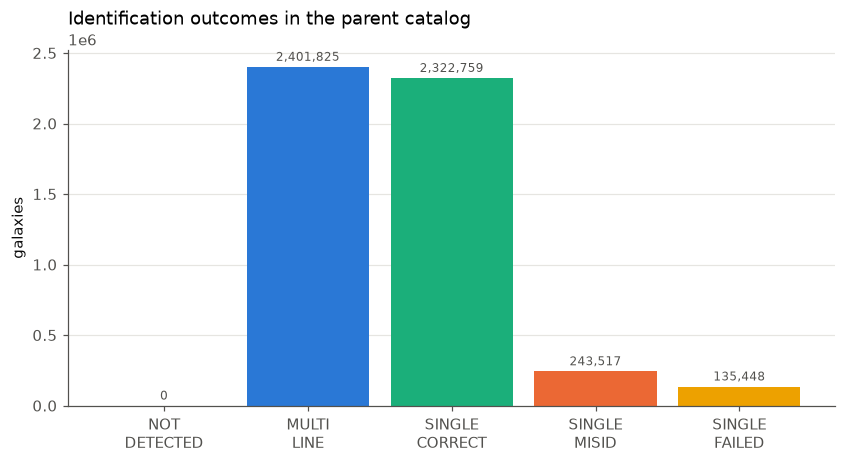

In [5]:
from romanmock.diagnostics import outcome_summary

cols = ["z_obs", "redshift_obs", "id_outcome", "n_det", "line_true", "line_assigned", "ra", "dec"]
pdata = parent.select(*cols).get_data("numpy", wrap_single=True)
summary = outcome_summary(pdata)
fig, ax = plt.subplots(figsize=(9, 4.2))
plotting.bar(ax, [k.replace("_", "\n") for k in summary], list(summary.values()), colors=[plotting.OUTCOME_COLORS[k] for k in summary])
ax.set_ylabel("galaxies"); ax.set_title("Identification outcomes in the parent catalog"); plt.show()

## dN/dz of the assigned-Hα sample and its contamination

An observer's Hα sample is every galaxy *assigned* Hα (`line_assigned == bit("Ha")`) with a
redshift. The contamination fraction `f_{i→j}(B)` uses that sample as denominator
(plan comment 4): here [O III] 5007 emitters at z ≈ 2.3 misidentified as Hα appear at z_obs ≈ 1.5.

Only three slices were processed, so the bins around z_obs ≈ 1.5 contain interlopers and no
true Hα emitters (there is no slice at z ≈ 1.5 in this demo), which is why the interloper fraction
reaches 100 % there. In a full run those bins are dominated by genuine Hα galaxies and the
fraction is a few per cent, set by the confusion matrix and the relative abundances.

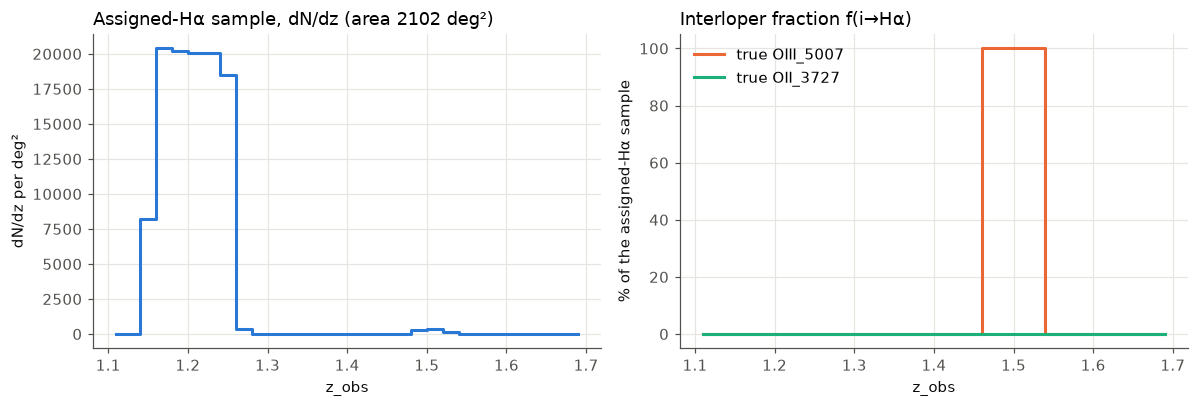

In [6]:
from romanmock.diagnostics import contamination_fraction, completeness, dndz
from romanmock.selection import sky_area_deg2

area = sky_area_deg2(parent, nside=256)
z_edges = np.linspace(1.1, 1.7, 31)
cont = contamination_fraction(pdata, pipe.line_set, z_edges, assigned_line="Ha")
zc = 0.5 * (z_edges[1:] + z_edges[:-1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.step(zc, cont["n_sample"] / (np.diff(z_edges) * area), where="mid", color=plotting.feature_color("Ha"))
ax1.set_xlabel("z_obs"); ax1.set_ylabel("dN/dz per deg²"); ax1.set_title(f"Assigned-Hα sample, dN/dz (area {area:.0f} deg²)")
for name in ["OIII_5007", "OII_3727"]:
    i = pipe.line_set.bit(name)
    ax2.step(zc, cont["fraction"][i] * 100, where="mid", color=plotting.feature_color(name), label=f"true {name}")
ax2.set_xlabel("z_obs"); ax2.set_ylabel("% of the assigned-Hα sample"); ax2.set_title("Interloper fraction f(i→Hα)"); ax2.legend()
plt.tight_layout(); plt.show()

In [7]:
comp = completeness(pdata, pipe.line_set, np.linspace(1.15, 1.26, 12), line="Ha")
print("Hα completeness per true-z bin:", np.round(comp["completeness"], 3))

Hα completeness per true-z bin: [0.938 0.937 0.936 0.935 0.934 0.934 0.933 0.931 0.931 0.931 0.93 ]


## Stage B: analysis samples

A `SampleConfig` defines cuts; `downsample` thins the sample to a target dN/dz with
`p_keep = target / mock` (never above 1). The target here is a smooth curve at 40% of the mock
density, just to demonstrate the mechanics; the mock dN/dz used in the ratio is estimated inside
the footprint and smoothed over one bin.

In [8]:
from romanmock.config import SampleConfig, DownsampleConfig
from romanmock.selection import build_footprint

box = {"type": "box", "ra_min": 0.0, "ra_max": 45.0, "dec_min": 55.0, "dec_max": 66.0}
footprint = build_footprint(box)
fp_area = sky_area_deg2(parent, 256, footprint=footprint)
sel = (pdata["line_assigned"] == pipe.line_set.bit("Ha")) & np.isfinite(pdata["z_obs"]) & footprint(pdata["ra"], pdata["dec"])
edges = np.linspace(1.15, 1.26, 12)
mock = dndz(pdata["z_obs"][sel], edges, fp_area)
zc = 0.5 * (edges[1:] + edges[:-1])
target = {"z": zc.tolist(), "dndz": (0.4 * np.convolve(mock, np.ones(3) / 3, mode="same")).tolist()}

samples = [
    SampleConfig(name="halpha_full", z_min=1.15, z_max=1.26, assigned_lines=["Ha"]),
    SampleConfig(name="halpha_box_downsampled", z_min=1.15, z_max=1.26, assigned_lines=["Ha"], footprint=box,
                 downsample=DownsampleConfig(target=target, z_edges=edges.tolist(), smooth_bins=1.0)),
]
cfg.output.overwrite = True
sample_files = pipe.build_samples(samples=samples)
sample_files

[romanmock] sample 'halpha_full': 4,504,016 of 5,103,549 parent galaxies


[romanmock] sample 'halpha_box_downsampled': area 137.80 deg^2, p_keep range 0.279-0.407
[romanmock] sample 'halpha_box_downsampled': 110,136 of 5,103,549 parent galaxies


[PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/samples/halpha_full.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/samples/halpha_box_downsampled.hdf5')]

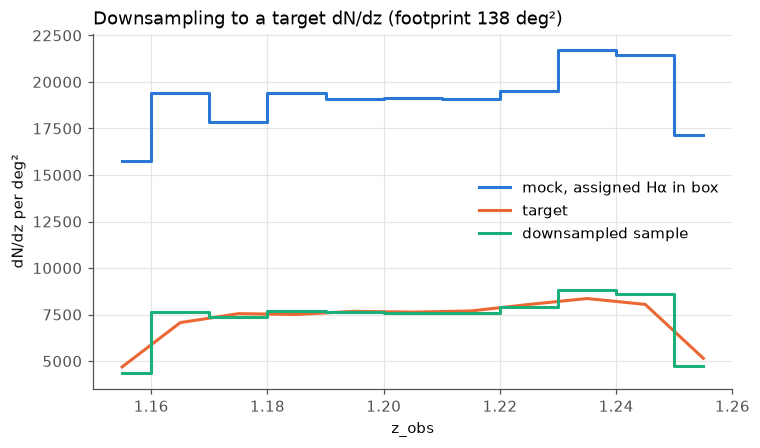

: null
    nside: 256
    smooth_bins: 1.0
n_galaxies: 110136
p_keep:
- 0.2794538978180357
- 0.39423543003701284
- 0.40715940057700495
- 0.39707622831014905
- 0.40201406584227356
- 0.39890769041297347
- 0.39775328318716574
- 0.4018004577261865
- 0.4038230993905651
- 0.3999711278383151
- 0.27898214532170873
z_edges:
- 1.15
- 1.16
- 1.17
- 1.18
- 1.19
- 1.2
- 1.21
- 1.22
- 1.23
- 1.24
- 1.25
- 1.26



In [9]:
ds_sample = oc.open(sample_files[1])
zs = ds_sample.select("z_obs").get_data("numpy")
fig, ax = plt.subplots()
ax.step(zc, mock, where="mid", color=plotting.CATEGORICAL[0], label="mock, assigned Hα in box")
ax.plot(zc, target["dndz"], color=plotting.CATEGORICAL[1], label="target")
ax.step(zc, dndz(zs, edges, fp_area), where="mid", color=plotting.CATEGORICAL[2], label="downsampled sample")
ax.set_xlabel("z_obs"); ax.set_ylabel("dN/dz per deg²"); ax.set_title(f"Downsampling to a target dN/dz (footprint {fp_area:.0f} deg²)")
ax.legend(); plt.show()
print(open(os.path.join(WORK, "parent", "samples", "halpha_box_downsampled_metadata.yaml")).read()[-400:])

The sample file keeps `gal_id`, `redshift_obs` (z_rsd), `z_obs`, `line_bitmask` and `id_outcome`,
so completeness, contamination and clustering can be checked against the truth, as the plan asks.